In [1]:
import sys
import subprocess
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


In [2]:
df = pd.read_csv("retail_sales_data_mba.csv")

In [3]:
df = df.drop_duplicates().copy()

if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in ["Age", "Quantity", "Price per Unit", "Total Amount"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Shape after removing duplicate rows:", df.shape)


Shape after removing duplicate rows: (1000, 9)


In [4]:
df = df.drop(['Transaction ID', 'Customer ID'], axis = 1)

Numeric columns: ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
Categorical columns: ['Gender', 'Product Category']


,count,mean,std,min,25%,50%,75%,max
Age,1000.0,41.392,13.681430,18.0,29.0,42.0,53.0,64.0
Quantity,1000.0,2.514,1.132734,1.0,1.0,3.0,4.0,4.0
Price per Unit,1000.0,179.890,189.681356,25.0,30.0,50.0,300.0,500.0
Total Amount,1000.0,456.000,559.997632,25.0,60.0,135.0,900.0,2000.0


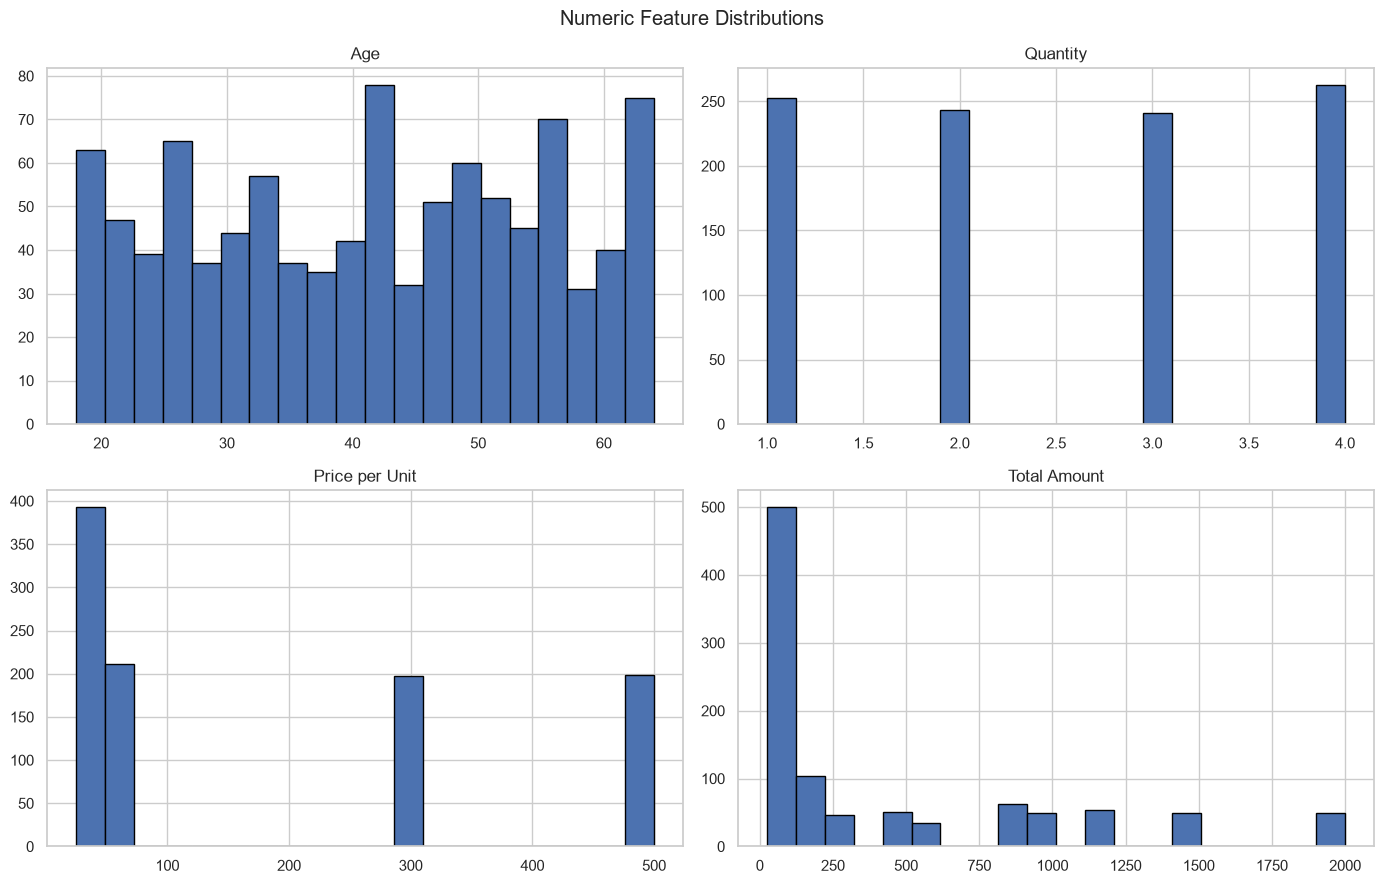

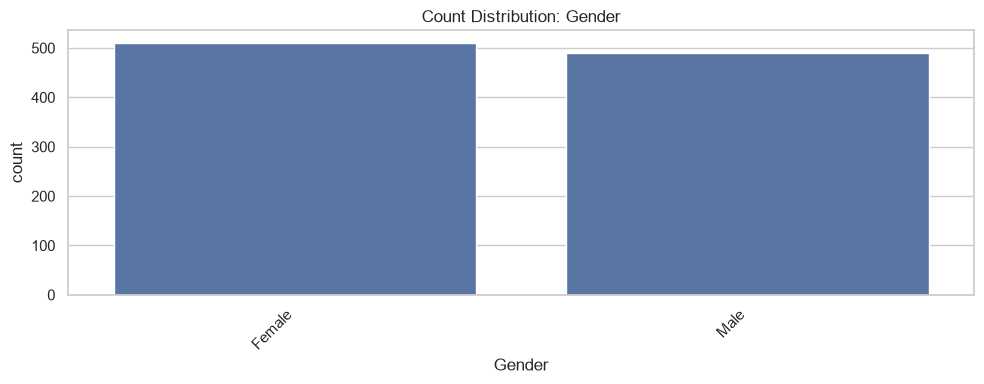

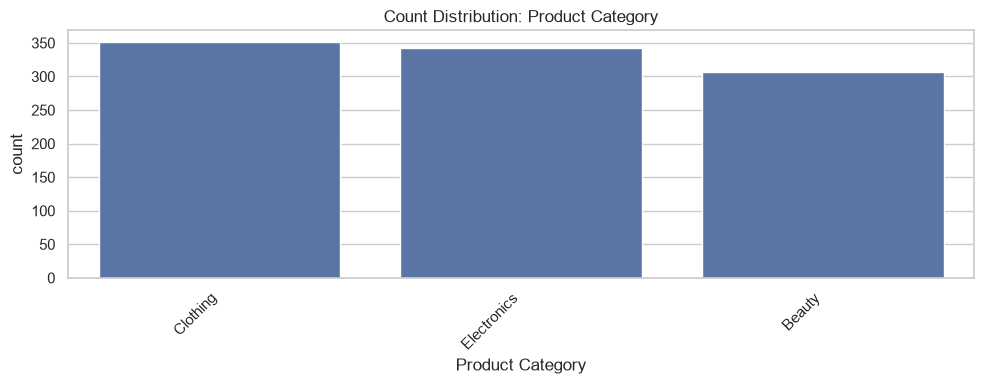

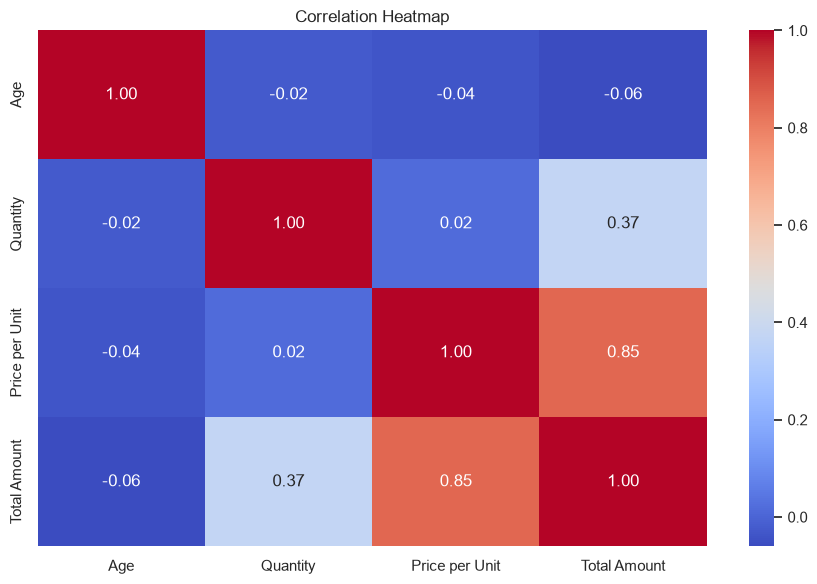

In [5]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

if numeric_cols:
    display(df[numeric_cols].describe().T)
    df[numeric_cols].hist(figsize=(14, 9), bins=20, edgecolor="black")
    plt.suptitle("Numeric Feature Distributions")
    plt.tight_layout()
    plt.show()

for col in categorical_cols:
    if df[col].nunique(dropna=True) <= 30:
        plt.figure(figsize=(10, 4))
        order = df[col].value_counts().index
        sns.countplot(data=df, x=col, order=order)
        plt.title(f"Count Distribution: {col}")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

if len(numeric_cols) >= 2:
    plt.figure(figsize=(9, 6))
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
